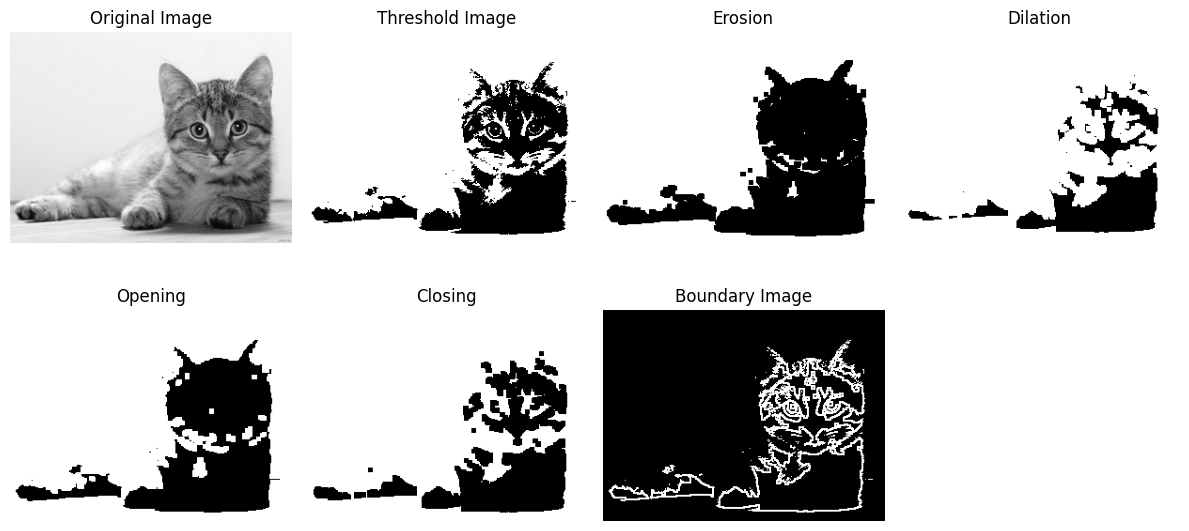

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the image as grayscale
image = cv2.imread("/Users/krishsondagar/Krish/sem_5/DSIP/cat.jpg", 0)

# Convert to a binary image (morphological operations show clearly on binary images)
_, thres_img = cv2.threshold(image, 128, 255, cv2.THRESH_BINARY)

# Define the kernel (structuring element)
kernel = np.ones((5, 5), np.uint8)

# Erosion
erosion = cv2.erode(thres_img, kernel, iterations=1)

# Dilation
dilation = cv2.dilate(thres_img, kernel, iterations=1)

# Opening (Erosion followed by Dilation)
opening = cv2.morphologyEx(thres_img, cv2.MORPH_OPEN, kernel)

# Closing (Dilation followed by Erosion)
closing = cv2.morphologyEx(thres_img, cv2.MORPH_CLOSE, kernel)

# Boundary = Dilated image - Binary image
boundary = cv2.subtract(dilation, thres_img)

# Display the original image and the results
titles = ['Original Image', 'Threshold Image', 'Erosion', 'Dilation',
          'Opening', 'Closing', 'Boundary Image']
images = [image, thres_img, erosion, dilation, opening, closing, boundary]

plt.figure(figsize=(12, 6))
for i in range(7):
    plt.subplot(2, 4, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()